## Methods

**Data.** Six nuclei images from the BBBC038 stage-1 test set (Broad Bioimage Benchmark Collection; nuclei images originally released for the 2018 Data Science Bowl), taken from the downloaded 65-image subset.

**Segmentation.** Pretrained Cellpose nuclei model (models.CellposeModel(gpu=True, model_type='nuclei'), cellpose 3.x pinned as cellpose<4 to avoid the v4/CPSAM API change), run on a T4 GPU in Google Colab with channels=[0, 0] (grayscale input).

**Quantification.** scikit-image measure.regionprops_table (area, perimeter, eccentricity, mean_intensity per nucleus) with an added circularity = 4π·area / perimeter² column; per-image means computed with pandas groupby('image_id'). Results saved as bbbc038_quantification.csv and the segmentation comparison as bbbc038_segmentation.png.


In [2]:
!pip install -q "cellpose<4"


In [3]:
!wget -q https://data.broadinstitute.org/bbbc/BBBC038/stage1_test.zip -O /content/stage1_test.zip
!unzip -q -o /content/stage1_test.zip -d /content/bbbc038
import glob
img_files = sorted(glob.glob('/content/bbbc038/*/images/*.png'))
print(len(img_files), 'images downloaded')
print(img_files[0])


65 images downloaded
/content/bbbc038/0114f484a16c152baa2d82fdd43740880a762c93f436c8988ac461c5c9dbe7d5/images/0114f484a16c152baa2d82fdd43740880a762c93f436c8988ac461c5c9dbe7d5.png


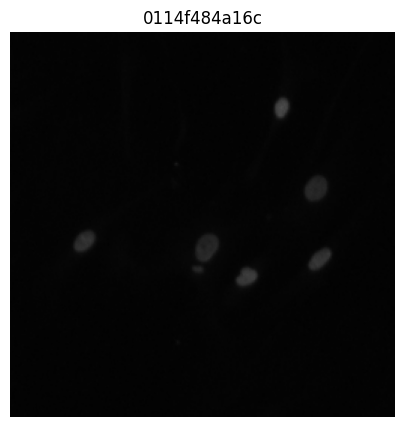

(256, 256, 4) uint8


In [4]:
from skimage import io
import matplotlib.pyplot as plt

img0 = io.imread(img_files[0])
plt.figure(figsize=(5, 5))
plt.imshow(img0, cmap='gray')
plt.axis('off')
plt.title(img_files[0].split('/')[-3][:12])
plt.show()
print(img0.shape, img0.dtype)


In [5]:
from cellpose import models
import numpy as np

model = models.CellposeModel(gpu=True, model_type='nuclei')

def load_gray(path):
    im = io.imread(path)
    if im.ndim == 3:
        im = im[..., :3].mean(axis=-1)
    return im

sel = img_files[:6]
imgs_b, masks_b, ids_b = [], [], []
for f in sel:
    g = load_gray(f)
    m, _, _ = model.eval(g, channels=[0, 0])
    imgs_b.append(g); masks_b.append(m)
    iid = f.split('/')[-3][:12]
    ids_b.append(iid)
    print(iid, '->', int(m.max()), 'nuclei')


100%|██████████| 25.3M/25.3M [00:00<00:00, 30.5MB/s]
/usr/local/lib/python3.13/dist-packages/cellpose/dynamics.py:760: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /pytorch/aten/src/ATen/Context.cpp:760.)
  coo = torch.sparse_coo_tensor(pt, torch.ones(pt.shape[1], device=pt.device, dtype=torch.int),


0114f484a16c -> 4 nuclei
0999dab07b11 -> 59 nuclei
0a849e0eb15f -> 42 nuclei
0e132f71c8b4 -> 2 nuclei
0ed3555a4bd4 -> 12 nuclei
0f1f896d9ae5 -> 21 nuclei


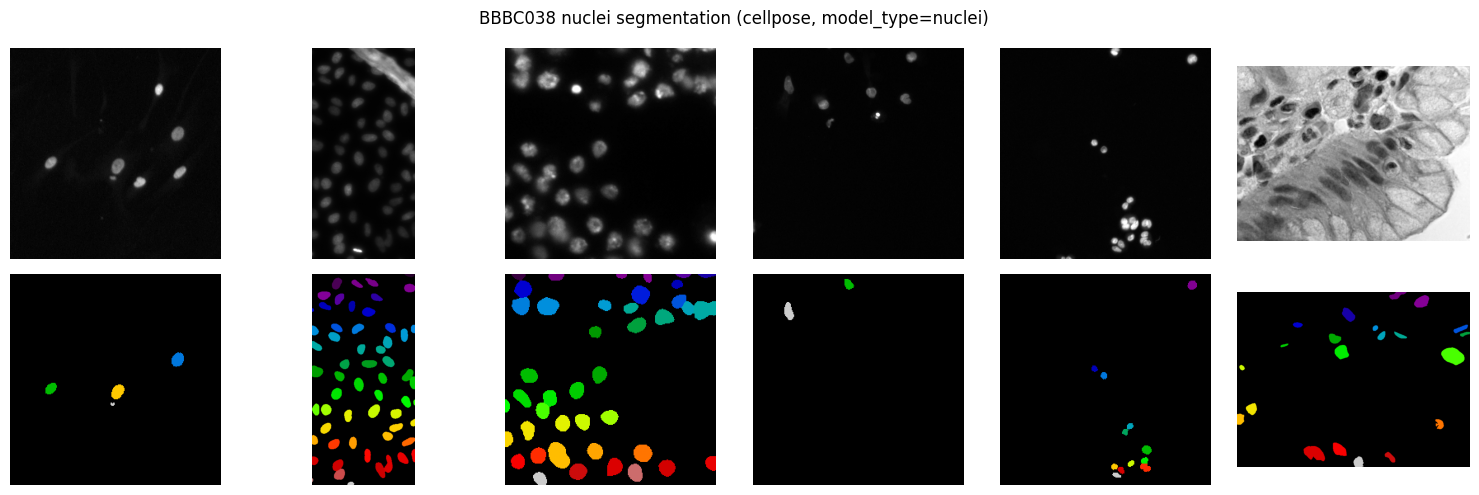

In [6]:
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for i in range(6):
    axes[0, i].imshow(imgs_b[i], cmap='gray'); axes[0, i].axis('off')
    axes[1, i].imshow(masks_b[i], cmap='nipy_spectral'); axes[1, i].axis('off')
axes[0, 0].set_ylabel('input'); axes[1, 0].set_ylabel('segmented')
plt.suptitle('BBBC038 nuclei segmentation (cellpose, model_type=nuclei)')
plt.tight_layout()
plt.savefig('/content/bbbc038_segmentation.png', dpi=150)
plt.show()


In [7]:
from skimage import measure
import pandas as pd

tables = []
for i in range(len(masks_b)):
    props = measure.regionprops_table(
        masks_b[i].astype(int),
        intensity_image=imgs_b[i],
        properties=('label', 'area', 'perimeter', 'eccentricity', 'mean_intensity'))
    df = pd.DataFrame(props)
    df['image_id'] = ids_b[i]
    tables.append(df)

quant = pd.concat(tables, ignore_index=True)
quant['circularity'] = 4 * 3.14159 * quant['area'] / quant['perimeter']**2
print(len(quant), 'nuclei quantified')
quant.head()


140 nuclei quantified


,label,area,perimeter,eccentricity,mean_intensity,image_id,circularity
0,1,205.0,52.870058,0.606273,33.707317,0114f484a16c,0.921603
1,2,146.0,43.798990,0.739338,40.842466,0114f484a16c,0.956388
2,3,212.0,52.870058,0.715168,34.537736,0114f484a16c,0.953072
3,4,17.0,13.656854,0.658653,32.705882,0114f484a16c,1.145400
4,1,146.0,56.384776,0.949076,51.143836,0999dab07b11,0.577083


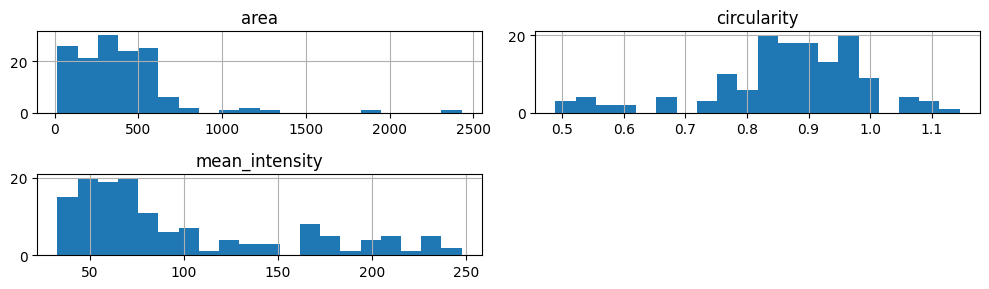

                    area  circularity  mean_intensity
image_id                                             
0114f484a16c  145.000000     0.994116       35.448350
0999dab07b11  431.559322     0.835942       57.574629
0a849e0eb15f  261.476190     0.902404       90.655555
0e132f71c8b4  145.000000     0.840359       62.294161
0ed3555a4bd4   62.666667     1.024258      159.938186
0f1f896d9ae5  756.904762     0.743227      211.718008


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [8]:
quant[['area', 'circularity', 'mean_intensity']].hist(bins=20, figsize=(10, 3))
plt.tight_layout(); plt.show()

per_image = quant.groupby('image_id')[['area', 'circularity', 'mean_intensity']].mean()
print(per_image)

quant.to_csv('/content/bbbc038_quantification.csv', index=False)
from google.colab import files
files.download('/content/bbbc038_quantification.csv')
files.download('/content/bbbc038_segmentation.png')
